# Chapter 51: Banks, Monitoring, Lending, and Credit Creation

This notebook reruns four worked examples from the chapter: delegated monitoring by a bank, charter-value discipline, relationship lending, and demand deposits as a commitment device. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def binomial_bars(ax, ks, probs, highlight=None, xlabel="Count", ylabel="Probability"):
    """Probability bars for a discrete distribution; ``highlight`` is a set of k to colour gold."""
    highlight = set(highlight or [])
    cols = [PALETTE["gold"] if k in highlight else PALETTE["teal"] for k in ks]
    ax.bar(ks, probs, color=cols, width=0.7)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def charter_value_choice(a_s, p_s, a_r, p_r, V):
    """Owner value of a safe and a risky portfolio with forfeitable charter value V.

    charter-value-discipline (chapter 51): 8 + 0.98(30) = 37.4 against 11 + 0.80(30) = 35 (safe);
    at V = 10, 17.8 against 19 (risky); threshold V* = (11 - 8) / (0.98 - 0.80) = 16.67.
    Returns safe, risky, v_star (None when survival probabilities are equal) and choice
    ('safe', 'risky' or 'tie').
    """
    safe = a_s + p_s * V
    risky = a_r + p_r * V
    v_star = (a_r - a_s) / (p_s - p_r) if p_s != p_r else None
    choice = "tie" if abs(safe - risky) <= 1e-9 else ("safe" if safe > risky else "risky")
    return {"safe": safe, "risky": risky, "v_star": v_star, "choice": choice}


def diamond_rajan(C, beta, cost, s):
    """Diamond-Rajan deposit commitment: pledgeable income, panic loss and expected surplus.

    diamond-rajan-liquidity-creation-fragility (chapter 51): C = 120, beta = 0.60, cost = 90.
    Outsider value beta C = 72; with deposits 90 is pledgeable (gain 18); completion surplus
    120 - 90 = 30; panic outcome 72 - 90 = -18; liquidation loss 120 - 72 = 48; expected
    surplus (1 - s)(30) + s(-18) = 30 - 48 s, positive for s < 30 / 48 = 0.625.
    """
    outside = beta * C
    complete = C - cost
    panic = outside - cost
    loss = C - outside
    return {"outside": outside, "pledgeable_deposits": cost, "gain": cost - outside, "complete": complete,
            "panic": panic, "loss": loss, "expected": (1 - s) * complete + s * panic,
            "s_star": complete / loss if loss > 0 else None}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(charter_value_choice=charter_value_choice, diamond_rajan=diamond_rajan)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'delegated-monitoring': {'savers': 100,
                          'loans': 10,
                          'check': 4000,
                          'checks': 1000,
                          'direct': 4000000,
                          'bank_monitoring': 40000,
                          'q': 0.1,
                          'high': 11.5,
                          'low': 4,
                          'promise': 100,
                          'expected_receipts': 107.5,
                          'default_cost': 40000000,
                          'p_default': 0.0701908,
                          'enforcement': 2807633,
                          'delegated': 2847633,
                          'correlated_enforcement': 4000000,
                          'correlated_total': 4040000},
 'charter-value-discipline': {'a_s': 8,
                              'p_s': 0.98,
                              'a_r': 11,
                              'p_r': 0.8,
                              'V': 30,
                              'safe': 37.4,
                              'risky': 35,
                              'V_2': 10,
                              'safe_2': 17.8,
                              'risky_2': 19,
                              'v_star': 16.67},
 'relationship-lending': {'principal': 100000,
                          'promise': 110000,
                          'collateral': 40000,
                          'p_o': 0.75,
                          'p_i': 0.9,
                          'outsider': 92500,
                          'incumbent': 103000,
                          'p_star': 106666.67,
                          'r_star_pct': 6.67},
 'diamond-rajan-liquidity-creation-fragility': {'C': 120,
                                                'beta': 0.6,
                                                'cost': 90,
                                                'outside': 72,
                                                'gain': 18,
                                                'complete': 30,
                                                'panic': -18,
                                                'loss': 48,
                                                's_star': 0.625},
 'constructed': {'delegated-monitoring': {'q': [0.05, 0.2], 'default_cost': [20000000]},
                 'charter-value-discipline': {'V': [20, 40], 'p_r': [0.7, 0.9]},
                 'relationship-lending': {'p': [0.85], 'collateral': [20000, 60000]},
                 'diamond-rajan-liquidity-creation-fragility': {'s': [0.1, 0.3, 0.8],
                                                                'beta': [0.5, 0.7]}}}


def delegated_monitoring(n_savers, n_loans, k, q, hi, lo, promise, D, correlated=False):
    """Direct versus delegated monitoring cost with a bank that can default (delegated-monitoring).

    Book (chapter 51): 100 savers, 10 loans, check cost 4,000; loans pay hi = 11.5 or lo = 4 (million)
    with failure probability 0.1; deposits promise 100. Default when F >= 3 failures,
    Pr = 0.0701908; expected enforcement 0.0701908 x 40m = 2,807,633; total 2,847,633 against
    a direct cost of 4,000,000. Perfect correlation: 0.1 x 40m + 40,000 = 4.04m.
    """
    direct = n_savers * n_loans * k
    monitoring = n_loans * k
    pmf = [math.comb(n_loans, j) * q ** j * (1 - q) ** (n_loans - j) for j in range(n_loans + 1)]
    receipts = [(n_loans - j) * hi + j * lo for j in range(n_loans + 1)]
    f_min = next(j for j in range(n_loans + 1) if receipts[j] < promise - 1e-12)
    p_default = q if correlated else sum(pmf[f_min:])
    enforcement = p_default * D
    return {"direct": direct, "monitoring": monitoring, "pmf": pmf, "receipts": receipts, "f_min": f_min,
            "expected_receipts": n_loans * ((1 - q) * hi + q * lo), "p_default": p_default,
            "enforcement": enforcement, "delegated": monitoring + enforcement}


def expected_repayment(p, promise, collateral):
    """Expected repayment p x promise + (1 - p) x collateral (relationship-lending).

    Book (chapter 51): 0.75(110,000) + 0.25(40,000) = 92,500; 0.90(110,000) + 0.10(40,000) = 103,000.
    """
    return p * promise + (1 - p) * collateral


def breakeven_promise(p, collateral, principal):
    """Promise that returns the principal in expectation: (principal - (1 - p) collateral) / p.

    relationship-lending (chapter 51): (100,000 - 0.10 x 40,000) / 0.90 = 106,666.67.
    """
    return (principal - (1 - p) * collateral) / p


def monitoring_picture(q=0.10, rho="independent", d=40):
    b = BV["delegated-monitoring"]
    corr = rho == "correlated"
    D = d * 1_000_000
    r = delegated_monitoring(b["savers"], b["loans"], b["check"], q, b["high"], b["low"], b["promise"], D, corr)
    fig, (ax1, ax2) = new_figure(ncols=2)
    if corr:
        bar_compare(ax1, ["All succeed", "All fail"], [1 - q, q], colors=["teal", "gold"],
                    value_labels=[num(1 - q, 2), num(q, 2)], ylabel="Probability", xlabel="Outcome of all ten loans")
        ax1.set_ylim(0, 1.2)
    else:
        ks = list(range(11))
        binomial_bars(ax1, ks, r["pmf"], highlight=range(r["f_min"], 11), xlabel="Failed loans F",
                      ylabel="Probability")
        ax1.set_xticks(ks)
        label(ax1, 10.4, max(r["pmf"]) * 0.75, f"gold: bank defaults, F >= {r['f_min']}\nPr = {num(r['p_default'], 7)}",
              col="gold", dx=0, dy=0, ha="right", va="center")
        ax1.set_ylim(0, max(r["pmf"]) * 1.12)
    win = r["delegated"] < r["direct"]
    bar_compare(ax2, ["Direct", "Bank"], [r["direct"] / 1e6, r["delegated"] / 1e6],
                colors=["grey", "teal" if win else "terracotta"],
                value_labels=[num(r["direct"] / 1e6, 3), num(r["delegated"] / 1e6, 3)],
                ylabel="Expected monitoring cost ($ million)", xlabel="Who monitors")
    ax2.set_ylim(0, 1.3 * max(r["direct"], r["delegated"]) / 1e6)
    verdict, tie = (("tie", True) if abs(r["delegated"] - r["direct"]) < 0.5 else
                    ("bank" if win else "direct", False))
    metrics = {"Pr(bank default)": num(r["p_default"], 7), "Expected enforcement": money(r["enforcement"], 0),
               "Delegated total": money(r["delegated"], 0), "Direct monitoring": money(r["direct"], 0),
               "Cheaper": "tie" if tie else ("Bank (delegated)" if win else "Direct monitoring")}
    if corr:
        pcalc = f"All ten loans fail together with probability {num(q, 2)}, so Pr(default) = {num(q, 2)}"
    else:
        pcalc = (f"The pool pays 115 - 7.5F million, below 100 once F >= {r['f_min']}; with failure probability "
                 f"{num(q, 2)}, Pr(F >= {r['f_min']}) = {num(r['p_default'], 7)}")
    interp = (f"Direct finance needs 100 x 10 = 1,000 checks, 1,000 x 4,000 = {money(r['direct'], 0)}. {pcalc}. "
              f"Expected enforcement is {num(r['p_default'], 9)} x {num(D, 0)} = {money(r['enforcement'], 0)}, and "
              f"adding 10 x 4,000 = 40,000 of monitoring gives {money(r['delegated'], 0)}, "
              + ("the same as direct monitoring." if tie else
                 (f"below the {money(r['direct'], 0)} direct cost, so the bank wins." if win else
                  f"above the {money(r['direct'], 0)} direct cost, so the bank loses its advantage.")))
    steps = ["Direct: 100 x 10 x 4,000 = 4,000,000",
             f"Pr(default) = {num(r['p_default'], 7)}" + (" (all loans fail together)" if corr else
                                                       f" (F >= {r['f_min']} of 10)"),
             f"Enforcement = {num(r['p_default'], 9)} x {num(D, 0)} = {num(r['enforcement'], 0)}",
             f"Delegated = 40,000 + {num(r['enforcement'], 0)} = {num(r['delegated'], 0)}"]
    alt = (f"Left: distribution of loan failures with failure probability {num(q, 2)}"
           + (", all loans moving together." if corr else ", default region shaded.")
           + f" Right: direct cost {money(r['direct'], 0)} against delegated cost {money(r['delegated'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def charter_picture(v=30, p_r=0.80):
    b = BV["charter-value-discipline"]
    a_s, p_s, a_r = b["a_s"], b["p_s"], b["a_r"]
    r = finance.charter_value_choice(a_s, p_s, a_r, p_r, v)
    vs = np.linspace(0, 50, 200)
    fig, ax = new_figure()
    ax.plot(vs, a_s + p_s * vs, color=PALETTE["teal"], linewidth=2.2, label="safe: 8 + 0.98 V")
    ax.plot(vs, a_r + p_r * vs, color=PALETTE["terracotta"], linewidth=2.2, label=f"risky: 11 + {num(p_r, 2)} V")
    vline(ax, r["v_star"], f"V* = {num(r['v_star'])}", col="grey", y_frac=0.97)
    win = r["safe"] if r["choice"] != "risky" else r["risky"]
    mark(ax, v, r["safe"], f"safe {num(r['safe'], 1)}", col="teal", dx=8, dy=-8, va="top")
    mark(ax, v, r["risky"], f"risky {num(r['risky'], 1)}", col="terracotta", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 52)
    ax.set_ylim(0, 65)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Charter value V ($ million)")
    ax.set_ylabel("Owner value ($ million)")
    names = {"safe": "Safe portfolio", "risky": "Risky portfolio", "tie": "tie"}
    metrics = {"Safe value": num(r["safe"], 1), "Risky value": num(r["risky"], 1), "Threshold V*": num(r["v_star"]),
               "Owners choose": names[r["choice"]]}
    interp = (f"Safe: 8 + 0.98 x {num(v, 0)} = 8 + {num(p_s * v, 1)} = {num(r['safe'], 1)}. Risky: 11 + {num(p_r, 2)} x "
              f"{num(v, 0)} = 11 + {num(p_r * v, 1)} = {num(r['risky'], 1)}. "
              + ("The two are equal." if r["choice"] == "tie" else
                 f"The {r['choice']} portfolio is worth more, so owners choose it.")
              + f" Indifference is at V* = 3 / (0.98 - {num(p_r, 2)}) = 3 / {num(p_s - p_r, 2)} = {num(r['v_star'])}.")
    steps = [f"Safe = 8 + 0.98 x {num(v, 0)} = {num(r['safe'], 1)}",
             f"Risky = 11 + {num(p_r, 2)} x {num(v, 0)} = {num(r['risky'], 1)}",
             f"V* = (11 - 8) / (0.98 - {num(p_r, 2)}) = 3 / {num(p_s - p_r, 2)} = {num(r['v_star'])}",
             f"V = {num(v, 0)} is {'above' if v > r['v_star'] else 'below'} V*, so {names[r['choice']].lower()} wins"]
    alt = (f"Owner value against charter value for the safe and risky portfolios; the lines cross at "
           f"V* = {num(r['v_star'])}. At V = {num(v, 0)} safe is {num(r['safe'], 1)} and risky {num(r['risky'], 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def relationship_picture(p=0.90, k=40000):
    b = BV["relationship-lending"]
    principal, promise = b["principal"], b["promise"]
    er = expected_repayment(p, promise, k)
    ps = breakeven_promise(p, k, principal)
    rate = ps / principal - 1
    lend = er >= principal - 1e-9
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Expected repayment"], [er], colors=["teal" if lend else "terracotta"],
                value_labels=[""], ylabel="Dollars", xlabel=f"Lender with p = {num(p, 2)}")
    hline(ax1, principal, "principal $100,000", col="ink")
    label(ax1, 0, er / 2, money(er, 0), col="ink", dx=0, dy=0, ha="center", va="center")
    ax1.set_ylim(0, 135_000)
    ax1.set_xlim(-0.8, 0.8)
    xs = np.linspace(95_000, 135_000, 200)
    ax2.plot(xs, p * xs + (1 - p) * k, color=PALETTE["navy"], linewidth=2.2)
    hline(ax2, principal, None, col="ink")
    below = ps < promise
    right_side = ps >= 115_000
    mark(ax2, ps, principal, f"P* = {money(ps)}", col="gold", dx=-8 if right_side else 8, dy=-10 if below else 10,
         va="top" if below else "bottom", ha="right" if right_side else "left")
    above = er > principal
    mark(ax2, promise, er, "110,000 promise", col="teal", dx=8, dy=10 if above else -10,
         va="bottom" if above else "top")
    ax2.set_xlim(95_000, 135_000)
    ax2.set_xticks([100_000, 115_000, 130_000], ["100,000", "115,000", "130,000"])
    ax2.set_yticks([80_000, 100_000, 120_000], ["80,000", "100,000", "120,000"])
    ax1.set_yticks([0, 50_000, 100_000], ["0", "50,000", "100,000"])
    ax2.set_ylim(70_000, 135_000)
    ax2.set_xlabel("Promised repayment (dollars)")
    ax2.set_ylabel("Expected repayment (dollars)")
    metrics = {"Expected repayment": money(er, 0), "Break-even promise P*": money(ps),
               "Break-even rate": f"{num(100 * rate)}%", "Decision at 110,000": "Lend" if lend else "Decline"}
    interp = (f"Expected repayment is {num(p, 2)} x 110,000 + {num(1 - p, 2)} x {num(k, 0)} = {num(p * promise, 0)} + "
              f"{num((1 - p) * k, 0)} = {money(er, 0)}, "
              + ("at or above the 100,000 principal, so the lender lends." if lend else
                 "below the 100,000 principal, so the lender declines.")
              + f" The break-even promise is (100,000 - {num(1 - p, 2)} x {num(k, 0)}) / {num(p, 2)} = {money(ps)}, a "
                f"success-state rate of {num(100 * rate)} percent.")
    steps = [f"E = {num(p, 2)} x 110,000 + {num(1 - p, 2)} x {num(k, 0)} = {num(er, 0)}",
             f"{num(er, 0)} {'>=' if lend else '<'} 100,000, so {'lend' if lend else 'decline'}",
             f"P* = (100,000 - {num((1 - p) * k, 0)}) / {num(p, 2)} = {num(ps)}",
             f"r* = {num(ps)} / 100,000 - 1 = {num(100 * rate)}%"]
    alt = (f"Left: expected repayment {money(er, 0)} against the 100,000 principal. Right: expected repayment rises "
           f"with the promise and reaches the principal at P* = {money(ps)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def deposits_picture(s=0.3, beta=0.6):
    b = BV["diamond-rajan-liquidity-creation-fragility"]
    r = finance.diamond_rajan(b["C"], beta, b["cost"], s)
    ss = np.linspace(0, 1, 200)
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot(ss, (1 - ss) * r["complete"] + ss * r["panic"], color=PALETTE["navy"], linewidth=2.2)
    ax1.axhline(0, color=PALETTE["grey"], linewidth=1)
    vline(ax1, r["s_star"], f"s* = {num(r['s_star'], 3)}", col="grey", y_frac=0.97,
          ha="right" if r["s_star"] > 0.7 else "left")
    mark(ax1, s, r["expected"], f"{num(r['expected'], 2)}", col="terracotta", dx=8, dy=8)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(-40, 40)
    ax1.set_xlabel("Panic probability s")
    ax1.set_ylabel("Expected surplus (dollars)")
    bar_compare(ax2, ["Completion", "Panic sale"], [r["complete"], r["panic"]], colors=["teal", "terracotta"],
                value_labels=[num(r["complete"], 0), num(r["panic"], 0)], ylabel="Net value (dollars)",
                xlabel="Outcome against the 90 cost")
    ax2.set_ylim(-45, 45)
    e = r["expected"]
    sign = "zero" if abs(e) < 1e-9 else ("positive" if e > 0 else "negative")
    metrics = {"Outsider value beta C": num(r["outside"], 0), "Pledgeable with deposits": num(r["pledgeable_deposits"], 0),
               "Liquidation loss": num(r["loss"], 0), "Expected surplus": num(e, 2),
               "Panic threshold s*": num(r["s_star"], 3)}
    interp = (f"An outsider recovers {num(beta, 1)} x 120 = {num(r['outside'], 0)}, so a panic sale nets "
              f"{num(r['outside'], 0)} - 90 = {num(r['panic'], 0)} and destroys 120 - {num(r['outside'], 0)} = "
              f"{num(r['loss'], 0)}. Expected surplus is (1 - {num(s, 3)}) x 30 + {num(s, 3)} x ({num(r['panic'], 0)}) "
              f"= {num((1 - s) * 30, 2)} + ({num(s * r['panic'], 2)}) = {num(e, 2)}, which is {sign}. It stays positive "
              f"while s < 30 / {num(r['loss'], 0)} = {num(r['s_star'], 3)}.")
    steps = [f"beta C = {num(beta, 1)} x 120 = {num(r['outside'], 0)}",
             f"Panic outcome = {num(r['outside'], 0)} - 90 = {num(r['panic'], 0)}",
             f"E = (1 - {num(s, 3)}) x 30 + {num(s, 3)} x ({num(r['panic'], 0)}) = {num(e, 2)}",
             f"s* = 30 / {num(r['loss'], 0)} = {num(r['s_star'], 3)}"]
    alt = (f"Left: expected surplus falls linearly in the panic probability and crosses zero at s* = "
           f"{num(r['s_star'], 3)}; at s = {num(s, 3)} it is {num(e, 2)}. Right: completion nets 30 and a panic sale "
           f"{num(r['panic'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Delegated monitoring: one monitor or a hundred

100 savers fund 10 loans; one check costs \$4,000, so direct finance needs $100(10)=1{,}000$ checks and \$4,000,000. A loan pays 11.5 or 4 million with failure probability 0.1; the bank promises 100 million and defaults when

$$\Pr(F\geq3)=1-\sum_{j=0}^{2}\binom{10}{j}(0.1)^j(0.9)^{10-j}\approx0.0701908.$$

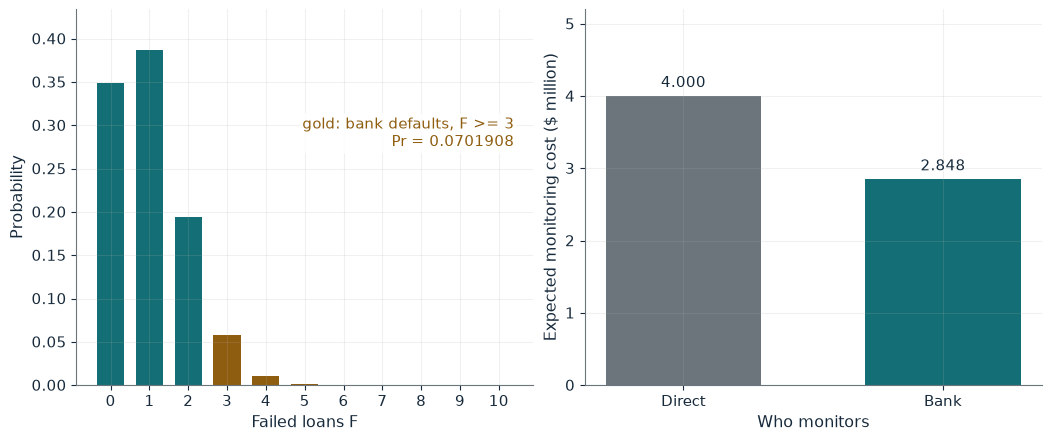

Pr(bank default)      0.0701908
Expected enforcement  $2,807,633
Delegated total       $2,847,633
Direct monitoring     $4,000,000
Cheaper               Bank (delegated)

Worked steps:
  1. Direct: 100 x 10 x 4,000 = 4,000,000
  2. Pr(default) = 0.0701908 (F >= 3 of 10)
  3. Enforcement = 0.070190826 x 40,000,000 = 2,807,633
  4. Delegated = 40,000 + 2,807,633 = 2,847,633

Direct finance needs 100 x 10 = 1,000 checks, 1,000 x 4,000 = $4,000,000. The pool pays 115 - 7.5F million, below 100 once F >= 3; with failure probability 0.10, Pr(F >= 3) = 0.0701908. Expected enforcement is 0.070190826 x 40,000,000 = $2,807,633, and adding 10 x 4,000 = 40,000 of monitoring gives $2,847,633, below the $4,000,000 direct cost, so the bank wins.


In [2]:
show(monitoring_picture(q=0.10, rho='independent', d=40))

Change one input, `q`, and hold the others at the book's values:

In [3]:
sweep(monitoring_picture, 'q', [0.05, 0.1, 0.2], {'rho': 'independent', 'd': 40}, ['Pr(bank default)', 'Delegated total', 'Cheaper'])

q | Pr(bank default) | Delegated total | Cheaper
0.05 | 0.0115036 | $500,142 | Bank (delegated)
0.1 | 0.0701908 | $2,847,633 | Bank (delegated)
0.2 | 0.3222005 | $12,928,019 | Direct monitoring


With independent loans the bank costs \$2,847,633 against \$4,000,000. If all loans fail together (`rho='correlated'`) enforcement is 0.1 x 40,000,000 and the total 4,040,000: the advantage disappears.

## 2. Charter-value discipline: franchise value keeps banks safe

Safe: 8 now, survival 0.98. Risky: 11 now, survival 0.80. Owner value is payoff plus survival times the charter value $V$, and indifference is

$$8+0.98V=11+0.80V.$$

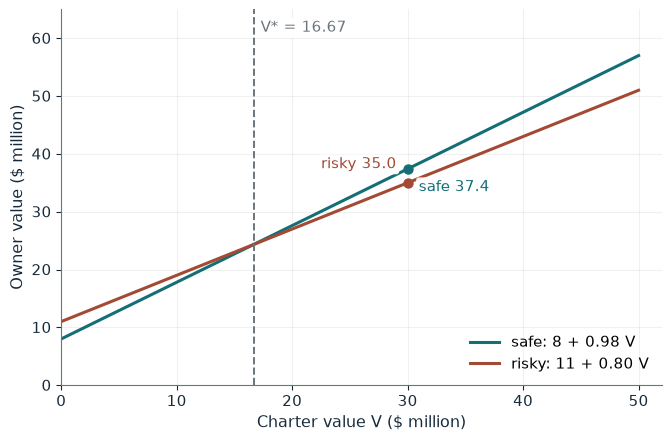

Safe value     37.4
Risky value    35.0
Threshold V*   16.67
Owners choose  Safe portfolio

Worked steps:
  1. Safe = 8 + 0.98 x 30 = 37.4
  2. Risky = 11 + 0.80 x 30 = 35.0
  3. V* = (11 - 8) / (0.98 - 0.80) = 3 / 0.18 = 16.67
  4. V = 30 is above V*, so safe portfolio wins

Safe: 8 + 0.98 x 30 = 8 + 29.4 = 37.4. Risky: 11 + 0.80 x 30 = 11 + 24.0 = 35.0. The safe portfolio is worth more, so owners choose it. Indifference is at V* = 3 / (0.98 - 0.80) = 3 / 0.18 = 16.67.


In [4]:
show(charter_picture(v=30, p_r=0.80))

Change one input, `v`, and hold the others at the book's values:

In [5]:
sweep(charter_picture, 'v', [10, 20, 30, 40], {'p_r': 0.8}, ['Safe value', 'Risky value', 'Owners choose'])

v | Safe value | Risky value | Owners choose
10 | 17.8 | 19.0 | Risky portfolio
20 | 27.6 | 27.0 | Safe portfolio
30 | 37.4 | 35.0 | Safe portfolio
40 | 47.2 | 43.0 | Safe portfolio


At V = 30 safety wins, 37.4 against 35; at V = 10 the gamble wins, 19 against 17.8. The threshold is V* = 3 / 0.18 = 16.67.

## 3. Relationship lending: what the relationship lender knows

A 100,000 loan promises 110,000; collateral yields 40,000 on failure. The outsider assigns $p=0.75$, the incumbent $p=0.90$. The break-even promise solves

$$0.90P^*+0.10(40{,}000)=100{,}000.$$

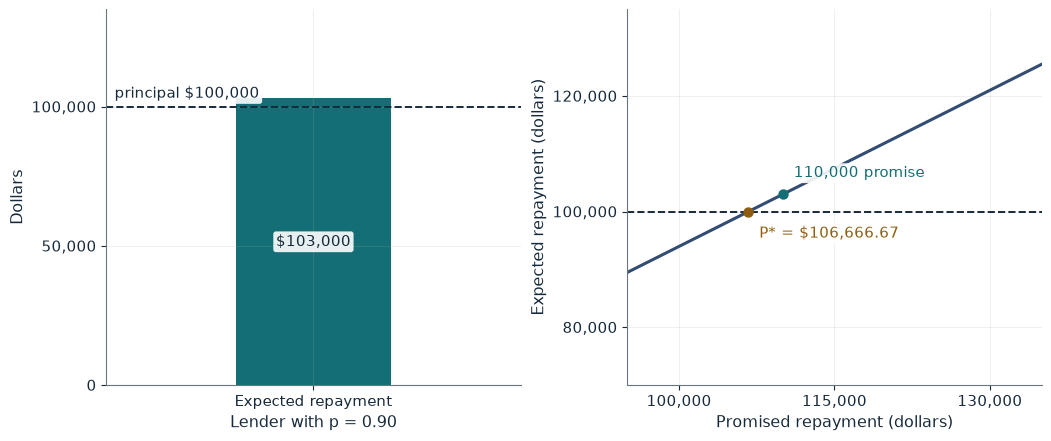

Expected repayment     $103,000
Break-even promise P*  $106,666.67
Break-even rate        6.67%
Decision at 110,000    Lend

Worked steps:
  1. E = 0.90 x 110,000 + 0.10 x 40,000 = 103,000
  2. 103,000 >= 100,000, so lend
  3. P* = (100,000 - 4,000) / 0.90 = 106,666.67
  4. r* = 106,666.67 / 100,000 - 1 = 6.67%

Expected repayment is 0.90 x 110,000 + 0.10 x 40,000 = 99,000 + 4,000 = $103,000, at or above the 100,000 principal, so the lender lends. The break-even promise is (100,000 - 0.10 x 40,000) / 0.90 = $106,666.67, a success-state rate of 6.67 percent.


In [6]:
show(relationship_picture(p=0.90, k=40000))

Change one input, `p`, and hold the others at the book's values:

In [7]:
sweep(relationship_picture, 'p', [0.75, 0.85, 0.9], {'k': 40000}, ['Expected repayment', 'Break-even promise P*', 'Decision at 110,000'])

p | Expected repayment | Break-even promise P* | Decision at 110,000
0.75 | $92,500 | $120,000.00 | Decline
0.85 | $99,500 | $110,588.24 | Decline
0.9 | $103,000 | $106,666.67 | Lend


The outsider expects 92,500 and declines; the incumbent expects 103,000 and lends. Its break-even promise is 106,666.67, a 6.67 percent rate, yet it can charge 110,000.

## 4. Diamond-Rajan: demand deposits as a commitment device

Collection value 120, outsider share 0.60 (so 72), project cost 90. With a panic probability $s$

$$(1-s)(30)+s(-18)=30-48s, \qquad s<\frac{30}{48}=0.625.$$

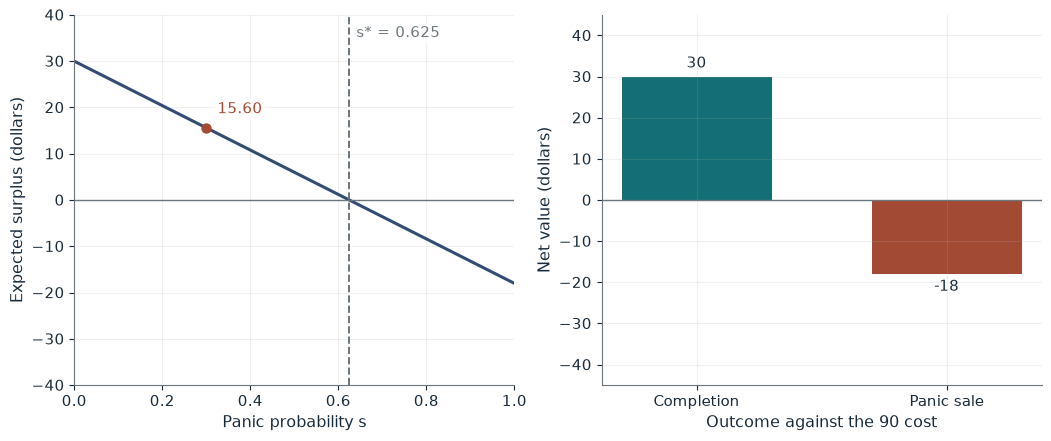

Outsider value beta C     72
Pledgeable with deposits  90
Liquidation loss          48
Expected surplus          15.60
Panic threshold s*        0.625

Worked steps:
  1. beta C = 0.6 x 120 = 72
  2. Panic outcome = 72 - 90 = -18
  3. E = (1 - 0.300) x 30 + 0.300 x (-18) = 15.60
  4. s* = 30 / 48 = 0.625

An outsider recovers 0.6 x 120 = 72, so a panic sale nets 72 - 90 = -18 and destroys 120 - 72 = 48. Expected surplus is (1 - 0.300) x 30 + 0.300 x (-18) = 21.00 + (-5.40) = 15.60, which is positive. It stays positive while s < 30 / 48 = 0.625.


In [8]:
show(deposits_picture(s=0.3, beta=0.6))

Change one input, `s`, and hold the others at the book's values:

In [9]:
sweep(deposits_picture, 's', [0.1, 0.3, 0.625, 0.8], {'beta': 0.6}, ['Expected surplus', 'Panic threshold s*'])

s | Expected surplus | Panic threshold s*
0.1 | 25.20 | 0.625
0.3 | 15.60 | 0.625
0.625 | 0.00 | 0.625
0.8 | -8.40 | 0.625


At s = 0.3 the expected surplus is 15.6; at s = 0.625 it is exactly zero, and above that deposits destroy value. A higher outsider share shrinks the liquidation loss and raises the threshold.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

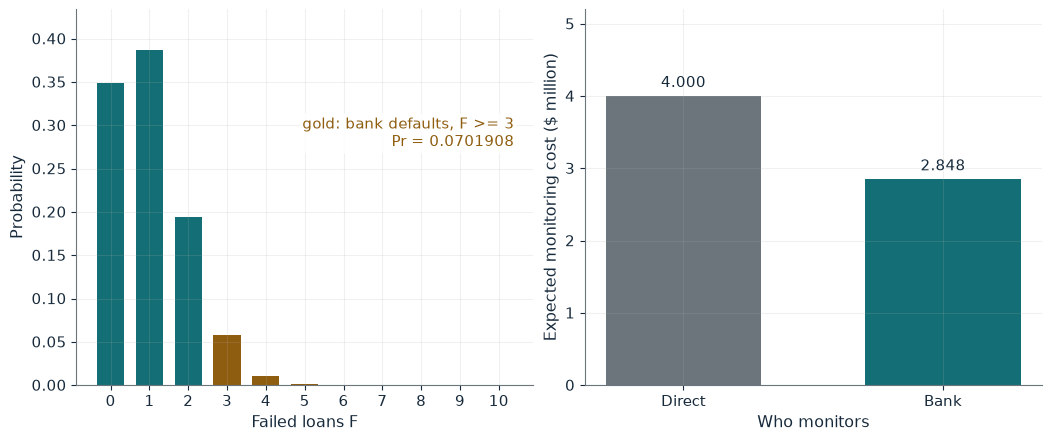

Pr(bank default)      0.0701908
Expected enforcement  $2,807,633
Delegated total       $2,847,633
Direct monitoring     $4,000,000
Cheaper               Bank (delegated)

Worked steps:
  1. Direct: 100 x 10 x 4,000 = 4,000,000
  2. Pr(default) = 0.0701908 (F >= 3 of 10)
  3. Enforcement = 0.070190826 x 40,000,000 = 2,807,633
  4. Delegated = 40,000 + 2,807,633 = 2,847,633

Direct finance needs 100 x 10 = 1,000 checks, 1,000 x 4,000 = $4,000,000. The pool pays 115 - 7.5F million, below 100 once F >= 3; with failure probability 0.10, Pr(F >= 3) = 0.0701908. Expected enforcement is 0.070190826 x 40,000,000 = $2,807,633, and adding 10 x 4,000 = 40,000 of monitoring gives $2,847,633, below the $4,000,000 direct cost, so the bank wins.


In [10]:
show(monitoring_picture(q=0.10, rho='independent', d=40))

## Practice

**1.** Under perfect correlation with failure probability 0.1 and a \$40 million default cost, what is the delegated cost?

<details><summary>Answer</summary>

0.1 x 40,000,000 + 40,000 = 4,040,000, above the 4,000,000 direct cost.

</details>

**2.** With V = 10, which portfolio do owners choose?

<details><summary>Answer</summary>

Safe 8 + 0.98 x 10 = 17.8; risky 11 + 0.80 x 10 = 19; the risky portfolio wins.

</details>

**3.** At beta = 0.6 and s = 0.3, what is expected surplus?

<details><summary>Answer</summary>

0.7 x 30 + 0.3 x (-18) = 21 - 5.4 = 15.6.

</details>